In [1]:
%pip install numpy pandas matplotlib scipy statsmodels openpyxl

Note: you may need to restart the kernel to use updated packages.


c:\Users\BIBLIOTECA03\Downloads\poster\.venv\Scripts\python.exe: No module named pip


In [1]:
# %% Importación de paquetes ============================

# Trabajar con rutas relativas en python
from pathlib import Path

# Módulos de numpy, pandas, matplotlib y scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import jarque_bera, probplot

# Módulos de statsmodels
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

In [4]:

# %% Cargar bases de datos en python usando rutas relativas =========================

# Obtener la ruta del directorio actual de trabajo
BASE_DIR = Path.cwd()

# Rutas de las bases de datos
ruta_exp = BASE_DIR / "Demanda.xlsx" # Base de datos

In [5]:
# %% =========================
# PRIMERA SERIE
# =============================

# Base de datos con la serie importada a python
#'''datos = pd.read_xlsx(ruta_exp, header=None)'''
# Usamos read_excel eliminando las primeras filas de metadatos definiendo header=2
datos = pd.read_excel(ruta_exp , header=2)

# Ver el tipo de objeto de la base de datos (Pandas.DataFrame)
print(type(datos))

<class 'pandas.DataFrame'>


In [6]:
# %% Creación del índice temporal de las series de tiempo

# 1. Crear la columna única de fecha a partir de Año, Mes y Día
fecha_texto = datos['Date - Year'].astype(str) + '-' + datos['Date - Month'].astype(str) + '-' + datos['Date - Day'].astype(str)
datos['Date'] = pd.to_datetime(fecha_texto, format='%Y-%B-%d')

# 2. Reemplazar y eliminar las 3 columnas antiguas de año, mes y día
datos = datos.drop(columns=['Date - Year', 'Date - Month', 'Date - Day'])

# 3. Establecer la nueva columna de fecha como el índice del DataFrame
datos = datos.set_index('Date')

# El tipo de objeto de la base de datos sigue siendo Pandas.DataFrame
print(type(datos))

# Ver primeras y últimas observaciones de la base de datos con la nueva estructura
print(datos.head()) # Primeras observaciones
print(datos.tail()) # Últimas observaciones


# %% Creación de la serie de tiempo de "demanda"

# La nueva serie de tiempo se va a llamar "Demanda" para mantener compatibilidad con el resto de tu código
serie = datos["Suma de Demanda Energia SIN"].copy()
serie = pd.to_numeric(serie, errors="coerce")
serie = serie.dropna() # Borrar missing values

# Ver el principio y final de la serie de tiempo
print(serie.head())
print(serie.tail())

# El tipo de objeto de la base de datos ahora es un Pandas.Series
print(type(serie))

# Ver algunas estadísticas descriptivas de la serie de tiempo
print(serie.describe())

<class 'pandas.DataFrame'>
            Suma de Demanda Energia SIN
Date                                   
2025-10-20                   236.585906
2025-10-21                   238.450828
2025-10-22                   239.883010
2025-10-23                   240.271402
2025-10-24                   241.451417
            Suma de Demanda Energia SIN
Date                                   
2026-10-11                   219.506259
2026-10-12                   219.453299
2026-10-13                   235.452010
2026-10-14                   244.366352
2026-10-15                   254.990340
Date
2025-10-20    236.585906
2025-10-21    238.450828
2025-10-22    239.883010
2025-10-23    240.271402
2025-10-24    241.451417
Name: Suma de Demanda Energia SIN, dtype: float64
Date
2026-10-11    219.506259
2026-10-12    219.453299
2026-10-13    235.452010
2026-10-14    244.366352
2026-10-15    254.990340
Name: Suma de Demanda Energia SIN, dtype: float64
<class 'pandas.Series'>
count    361.000000
mean     

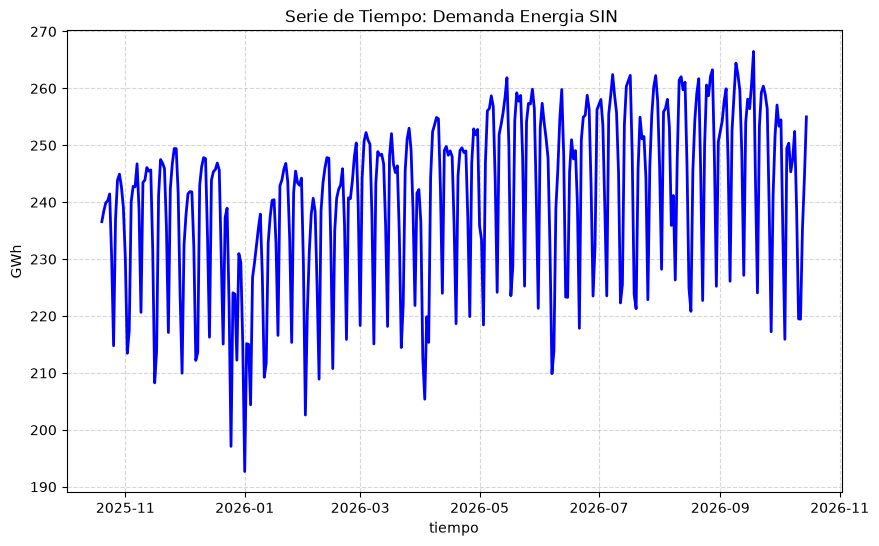

In [7]:

plt.figure(figsize=(10, 6))
plt.plot( datos['Suma de Demanda Energia SIN'], color='blue', linewidth=2)
plt.title('Serie de Tiempo: Demanda Energia SIN ')
plt.xlabel('tiempo')
plt.ylabel('GWh')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()